In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import torch

from torchvision.datasets import MNIST
from sklearn.metrics import adjusted_rand_score, silhouette_score

SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)

print("NumPy:", np.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


NumPy: 2.4.4
PyTorch: 2.15.0+cpu
CUDA available: False


In [2]:
train_dataset = MNIST(root='./data', train=True, download=True, transform=None)
test_dataset = MNIST(root='./data', train=False, download=True, transform=None)

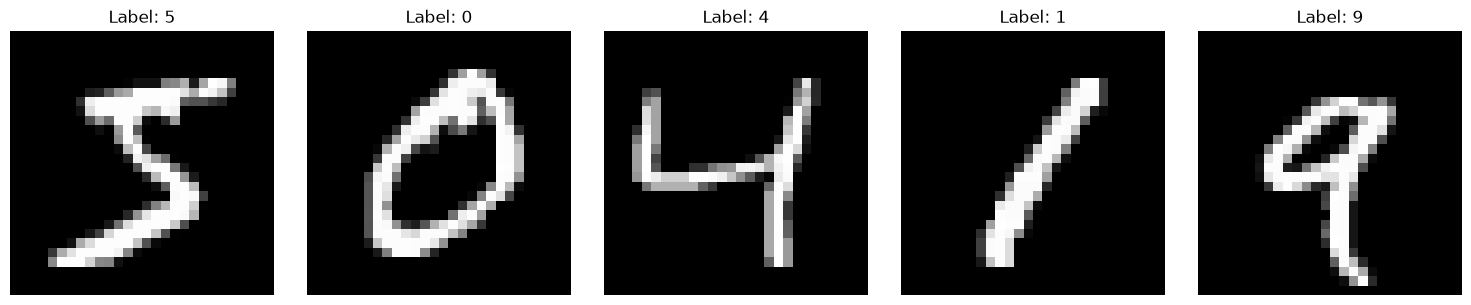

In [3]:
fig ,axes = plt.subplots(1, 5, figsize=(15, 3)) 
for i,ax in enumerate(axes.flat): 
       image ,label = train_dataset[i]
       ax.imshow(image, cmap='gray')
       ax.set_title(f'Label: {label}')
       ax.axis('off')

plt.tight_layout()
plt.show()

In [4]:
X_train=train_dataset.data.numpy()
X_test = test_dataset.data.numpy()
y_train = train_dataset.targets.numpy()
y_test = test_dataset.targets.numpy()

X_train = X_train.reshape(-1,784)
X_test= X_test.reshape(-1,784)
print("X_train", X_train.shape)
print("X_test",X_test.shape)
print("y_train:",y_train.shape)
print("y_test:",y_test.shape)

X_train (60000, 784)
X_test (10000, 784)
y_train: (60000,)
y_test: (10000,)


In [5]:
X_train = X_train.astype(np.float32) / 255.0 
X_test = X_test.astype(np.float32) / 255.0 
print("X_train:", X_train.shape, "X_test:", X_test.shape) 
print("y_train:", y_train.shape, "y_test:", y_test.shape) 

X_train: (60000, 784) X_test: (10000, 784)
y_train: (60000,) y_test: (10000,)


In [6]:
CONFIG = { 
       "n_clusters": 10, 
       "n_init": 10, 
       "max_iter": 300, 
       "random_state": SEED, 
       "verbose": 0, 
       "epochs": [1 ,2,3,5,10,15], 
       "n_runs": 5,
       # Full MNIST silhouette scoring is O(n^2) and can exhaust RAM.
       "silhouette_sample_size": 2000
       }
pd.DataFrame(CONFIG.items(), columns=["Parameter", "Value"] )

,Parameter,Value
0,n_clusters,10
1,n_init,10
2,max_iter,300
3,random_state,42
4,verbose,0
5,epochs,"[1, 2, 3, 5, 10, 15]"
6,n_runs,5
7,silhouette_sample_size,2000


In [7]:
from pathlib import Path 
path = Path("results")
path.mkdir(exist_ok=True)
path = Path("results/benchmark") 
path.mkdir(exist_ok=True)
np.savez_compressed(path / "mnist_data.npz", X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test)
print("MNIST data saved to:", path / "mnist_data.npz") 


MNIST data saved to: results\benchmark\mnist_data.npz


In [8]:
from sklearn.cluster import KMeans 
from sklearn.metrics import adjusted_rand_score, silhouette_score ,pairwise_distances_argmin_min
import time 
import numpy as np 


In [9]:
def calculate_mse(X, centroids, labels):
    distances = np.linalg.norm(X - centroids[labels], axis=1)
    mse = np.mean(distances ** 2)
    return mse

In [10]:
K= 10 
rng = np.random.default_rng(SEED) 
initial_indices = rng.choice(X_train.shape[0], size=K, replace=False)
initial_centroids = X_train[initial_indices].copy()
print("Initial centroids shape:", initial_centroids.shape)

Initial centroids shape: (10, 784)


In [11]:
max_epoch = max(CONFIG["epochs"])
history = []

start_time = time.time()
for epoch in range(1, max_epoch + 1):
    kmeans = KMeans(n_clusters=K, init=initial_centroids, n_init=1, max_iter=1, random_state=SEED)
    kmeans.fit(X_train)
    
    centroids = kmeans.cluster_centers_
    labels = kmeans.labels_
    
    mse = calculate_mse(X_train, centroids, labels)
    ari = adjusted_rand_score(y_train, labels)
    silhouette = silhouette_score(
        X_train,
        labels,
        sample_size=CONFIG["silhouette_sample_size"],
        random_state=SEED,
    )
    initial_centroids = centroids.copy()
    
    history.append({
        'epoch': epoch,
        'mse': mse,
        'ari': ari,
        'silhouette': silhouette
    })
    
    print(f"Epoch {epoch}: MSE={mse:.4f}, ARI={ari:.4f}, Silhouette={silhouette:.4f}")

Epoch 1: MSE=42.7405, ARI=0.1887, Silhouette=0.0478
Epoch 2: MSE=41.0192, ARI=0.2637, Silhouette=0.0572
Epoch 3: MSE=40.3296, ARI=0.3149, Silhouette=0.0598
Epoch 4: MSE=39.9524, ARI=0.3439, Silhouette=0.0614
Epoch 5: MSE=39.7540, ARI=0.3591, Silhouette=0.0621
Epoch 6: MSE=39.6400, ARI=0.3687, Silhouette=0.0632
Epoch 7: MSE=39.5721, ARI=0.3740, Silhouette=0.0637
Epoch 8: MSE=39.5323, ARI=0.3765, Silhouette=0.0643
Epoch 9: MSE=39.5058, ARI=0.3783, Silhouette=0.0647
Epoch 10: MSE=39.4876, ARI=0.3799, Silhouette=0.0648
Epoch 11: MSE=39.4744, ARI=0.3812, Silhouette=0.0649
Epoch 12: MSE=39.4637, ARI=0.3822, Silhouette=0.0652
Epoch 13: MSE=39.4542, ARI=0.3832, Silhouette=0.0654
Epoch 14: MSE=39.4452, ARI=0.3847, Silhouette=0.0658
Epoch 15: MSE=39.4355, ARI=0.3857, Silhouette=0.0656


In [12]:
history_df = pd.DataFrame(history)
history_df.to_csv(path / "kmeans_history.csv", index=False)
print("Benchmark history saved to:", path / "kmeans_history.csv")
history_df

Benchmark history saved to: results\benchmark\kmeans_history.csv


,epoch,mse,ari,silhouette
0,1,42.740467,0.188659,0.047806
1,2,41.019207,0.263746,0.057250
2,3,40.329636,0.314854,0.059805
3,4,39.952385,0.343867,0.061438
4,5,39.753971,0.359096,0.062121
5,6,39.639992,0.368714,0.063237
6,7,39.572102,0.373977,0.063668
7,8,39.532295,0.376500,0.064322
8,9,39.505798,0.378275,0.064736
9,10,39.487598,0.379886,0.064825


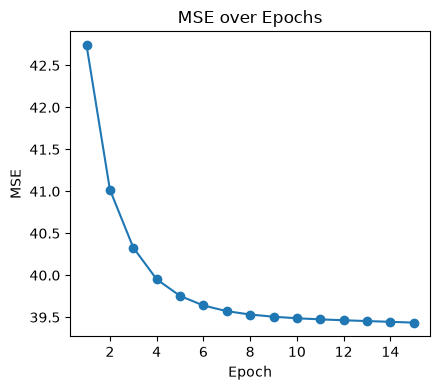

In [13]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.plot(history_df['epoch'], history_df['mse'], marker='o')
plt.title('MSE over Epochs')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.tight_layout()
plt.show()


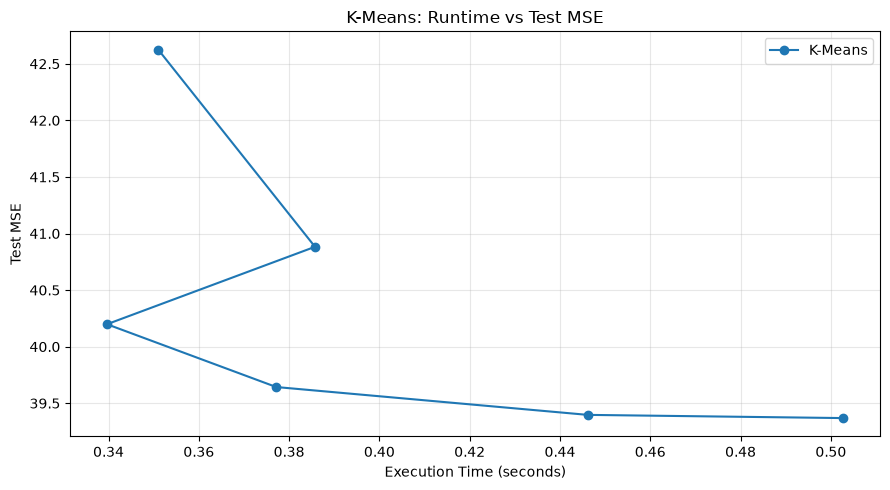

In [15]:
benchmark_rows = []
rng = np.random.default_rng(SEED)
benchmark_indices = rng.choice(X_train.shape[0], size=K, replace=False)
benchmark_initial_centroids = X_train[benchmark_indices].copy()

for n_iterations in CONFIG["epochs"]:
    start_time = time.perf_counter()
    benchmark_kmeans = KMeans(
        n_clusters=K,
        init=benchmark_initial_centroids,
        n_init=1,
        max_iter=n_iterations,
        random_state=SEED,
    )
    benchmark_kmeans.fit(X_train)
    elapsed = time.perf_counter() - start_time
    test_labels = benchmark_kmeans.predict(X_test)
    test_mse = calculate_mse(X_test, benchmark_kmeans.cluster_centers_, test_labels)
    benchmark_rows.append({
        "iterations": n_iterations,
        "time_sec": elapsed,
        "test_mse": test_mse,
    })

kmeans_history = pd.DataFrame(benchmark_rows)
kmeans_history.to_csv(path / "kmeans_runtime_history.csv", index=False)

plt.figure(figsize=(9, 5))

plt.plot(
    kmeans_history["time_sec"],
    kmeans_history["test_mse"],
    marker="o",
    label="K-Means"
)

plt.xlabel("Execution Time (seconds)")
plt.ylabel("Test MSE")
plt.title("K-Means: Runtime vs Test MSE")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(path / "kmeans_runtime_vs_mse.png", dpi=200)
plt.show()
